# Time-series forecasting: inference test (CPU)

Runs three zero-shot forecasting models on 10 real time series. None of them is trained on this data:
each model gets the history, predicts the next `horizon` steps, and is scored against the real values that were hidden from it.

| Model | Hugging Face id | Size | Runs on CPU? |
|---|---|---|---|
| Toto 2.0 | `Datadog/Toto-2.0-{size}` | 22m / **313m** (used here) / 1B / 2.5B | 22m, 313m: **yes**. 1B: yes with ~8 GB+ free RAM. **2.5B: not on this laptop.** Its weights are 9.1 GB in fp32, so it needs roughly 12 GB+ of free RAM or a GPU. |
| TiRex-2 | `NX-AI/TiRex-2` | ~83M params | **yes** (set `TORCHDYNAMO_DISABLE=1`, done below, unless a C++ compiler is installed) |
| Chronos-2 | `amazon/chronos-2` | ~120M params | **yes** |

**Not included: MOMENT-1-base.** Its forecasting head is untrained until you fine-tune it, so it cannot forecast zero-shot.
Its zero-shot uses are embeddings, imputation and anomaly detection.

**What every model returns here:** 9 quantiles (0.1, 0.2, …, 0.9) for each future step.
- **0.5 = the median:** the single best guess.
- **0.1 to 0.9:** an 80% range. If a model is well calibrated, about 80% of the real values fall inside it.

**Scores used:**
- **MAE:** average absolute error, in the series' own units.
- **MASE:** MAE divided by the error of a "repeat last season" guess on the history. Below 1 means the model beats that simple rule.
- **Coverage:** the % of real values inside the 80% range. The ideal is about 80%.

In [1]:
import os
os.environ["TORCHDYNAMO_DISABLE"] = "1"   # TiRex-2 calls torch.compile; this turns it into a no-op (no C++ compiler needed)

import gc, json, time, warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__, "| threads", torch.get_num_threads())

DATA = Path("data/series")
OUT = Path("outputs"); (OUT / "plots").mkdir(parents=True, exist_ok=True)

def date_axis(ax, maxticks=7):
    # compact date labels ("Mar", "09", "2018-Jun") so ticks never overlap
    loc = mdates.AutoDateLocator(maxticks=maxticks)
    ax.xaxis.set_major_locator(loc); ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(loc))

device: cpu | torch 2.15.0+cpu | threads 4


## Settings

In [2]:
TOTO_SIZE = "313m"   # 22m | 313m | 1B | 2.5B   (2.5B needs ~12 GB+ free RAM or a GPU)
QUANTILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   # all three models return these 9

## The 10 test series

The last `horizon` points of each series are hidden from the models and used as the answer key.

| # | Series | Frequency | What's in it |
|---|---|---|---|
| 01 | Airline passengers 1949–60 | monthly | trend plus yearly seasonality that grows over time |
| 02 | CO2 at Mauna Loa 1958–2026 | monthly | smooth trend plus a yearly cycle |
| 03 | Sunspots | monthly | an irregular ~11-year cycle, hard to forecast |
| 04 | Melbourne daily min temperature | daily | yearly cycle with lots of day-to-day noise |
| 05 | Daily female births, California 1959 | daily | mostly noise, little structure |
| 06 | Quebec car sales 1960–68 | monthly | short (108 points), trend plus seasonality |
| 07 | Transformer oil temperature (ETTh1) | hourly | drifting level, weak daily cycle |
| 08 | Transformer load (ETTh1) | hourly | daily cycle |
| 09 | Bike rentals, Washington DC | hourly | strong daily and weekly pattern |
| 10 | Bike rentals, Washington DC | daily | weekly pattern; has covariates (`workingday`, `temp`) |

,freq,length,horizon,season,unit
01_airline_passengers,MS,144,24,12,passengers (thousands)
02_co2_mauna_loa,MS,823,36,12,CO2 (ppm)
03_sunspots,MS,2048,60,132,sunspot number
04_melbourne_min_temp,D,3652,60,365,min temperature (C)
05_female_births,D,365,30,7,births per day
06_car_sales,MS,108,12,12,cars sold
07_ett_oil_temp,h,3000,96,24,oil temperature (C)
08_ett_load,h,3000,96,24,high useful load
09_bike_hourly,h,3000,168,168,rentals per hour
10_bike_daily,D,731,30,7,rentals per day


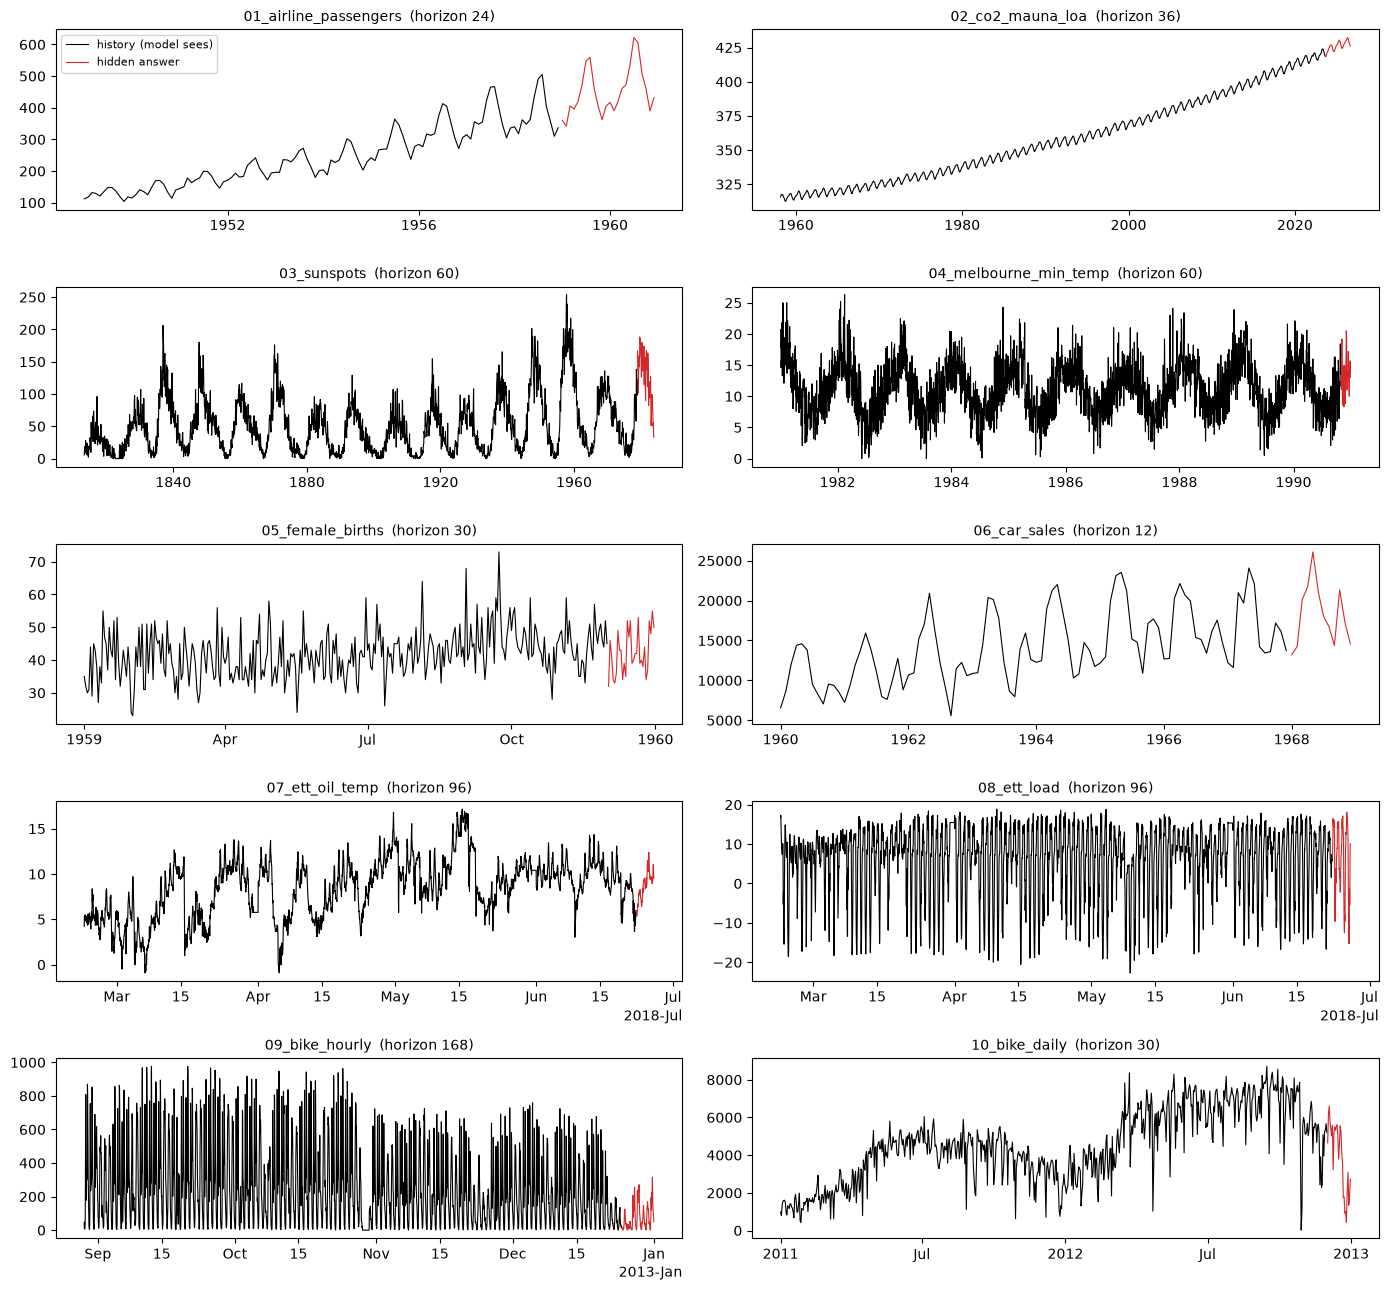

In [3]:
meta = json.loads((DATA / "meta.json").read_text())
SERIES = {name: pd.read_csv(DATA / f"{name}.csv", parse_dates=["timestamp"]) for name in meta}
display(pd.DataFrame(meta).T[["freq", "length", "horizon", "season", "unit"]])

fig, axes = plt.subplots(5, 2, figsize=(14, 13))
for ax, (name, df) in zip(axes.flat, SERIES.items()):
    h = meta[name]["horizon"]
    ax.plot(df.timestamp[:-h], df.target[:-h], lw=0.8, color="black", label="history (model sees)")
    ax.plot(df.timestamp[-h:], df.target[-h:], lw=0.8, color="tab:red", label="hidden answer")
    ax.set_title(f"{name}  (horizon {h})", fontsize=10)
    date_axis(ax)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Helpers: scoring, plotting, bookkeeping

In [4]:
def split(name):
    df, h = SERIES[name], meta[name]["horizon"]
    return df.iloc[:-h], df.iloc[-h:]

def scores(name, q):
    # q: array (9, horizon) of quantiles 0.1..0.9
    hist, test = split(name)
    y, ctx, m = test.target.values, hist.target.values, meta[name]["season"]
    mae = np.abs(q[4] - y).mean()
    scale = np.abs(ctx[m:] - ctx[:-m]).mean()
    cover = ((y >= q[0]) & (y <= q[8])).mean() * 100
    return {"MAE": mae, "MASE": mae / scale, "coverage_80": cover}

FORECASTS, TIMES, LOADS = {}, {}, {}   # FORECASTS[model][series] = (9, horizon) array

def record(model, name, q, seconds):
    FORECASTS.setdefault(model, {})[name] = np.asarray(q, dtype=float)
    TIMES.setdefault(model, {})[name] = seconds

def plot_forecast(name, models, show_hist=None, ax=None):
    hist, test = split(name)
    h = len(test); show_hist = show_hist or min(len(hist), 4 * h)
    ax = ax or plt.subplots(figsize=(12, 3.5))[1]
    ax.plot(hist.timestamp[-show_hist:], hist.target[-show_hist:], color="black", lw=1, label="history")
    ax.plot(test.timestamp, test.target, color="tab:red", lw=1.3, label="actual")
    for model, color in zip(models, ["tab:blue", "tab:green", "tab:purple", "tab:orange", "tab:gray"]):
        q = FORECASTS[model][name]
        s = scores(name, q)
        ax.plot(test.timestamp, q[4], color=color, lw=1.3, label=f"{model} median (MASE {s['MASE']:.2f})")
        ax.fill_between(test.timestamp, q[0], q[8], color=color, alpha=0.15)
    date_axis(ax)
    ax.set_title(f"{name} [{meta[name]['unit']}]  shaded = 80% range", fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
    return ax

def show_model(model):
    rows = [{"series": n, **scores(n, q), "seconds": TIMES[model][n]} for n, q in FORECASTS[model].items()]
    df = pd.DataFrame(rows).set_index("series")
    display(df.round(2))
    print(f"{model}: mean MASE {df.MASE.mean():.2f} | mean coverage {df.coverage_80.mean():.0f}% "
          f"| avg {df.seconds.mean():.2f}s per series | load {LOADS.get(model, 0):.1f}s")
    fig, axes = plt.subplots(5, 2, figsize=(15, 15))
    for ax, name in zip(axes.flat, FORECASTS[model]):
        plot_forecast(name, [model], ax=ax)
    plt.tight_layout(); plt.show()

def free(*objs):
    for o in objs: del o
    gc.collect()

## Baseline: seasonal naive (not a model)

> This is a reference point, not a model. It forecasts that each future step equals the value one season earlier,
> for example the same month last year.
> Its 80% range comes from how far off that rule was on the history.
> If a foundation model can't beat this, it isn't adding value on that series.

,MAE,MASE,coverage_80,seconds
series,,,,
01_airline_passengers,43.83,1.53,25.00,0.0
02_co2_mauna_loa,4.46,2.74,0.00,0.0
03_sunspots,39.29,1.54,55.00,0.0
04_melbourne_min_temp,2.88,0.93,86.67,0.0
05_female_births,6.97,0.95,90.00,0.0
06_car_sales,1485.17,0.96,83.33,0.0
07_ett_oil_temp,2.74,1.59,57.29,0.0
08_ett_load,4.71,1.31,71.88,0.0
09_bike_hourly,90.23,1.27,74.40,0.0


SeasonalNaive: mean MASE 1.45 | mean coverage 60% | avg 0.00s per series | load 0.0s


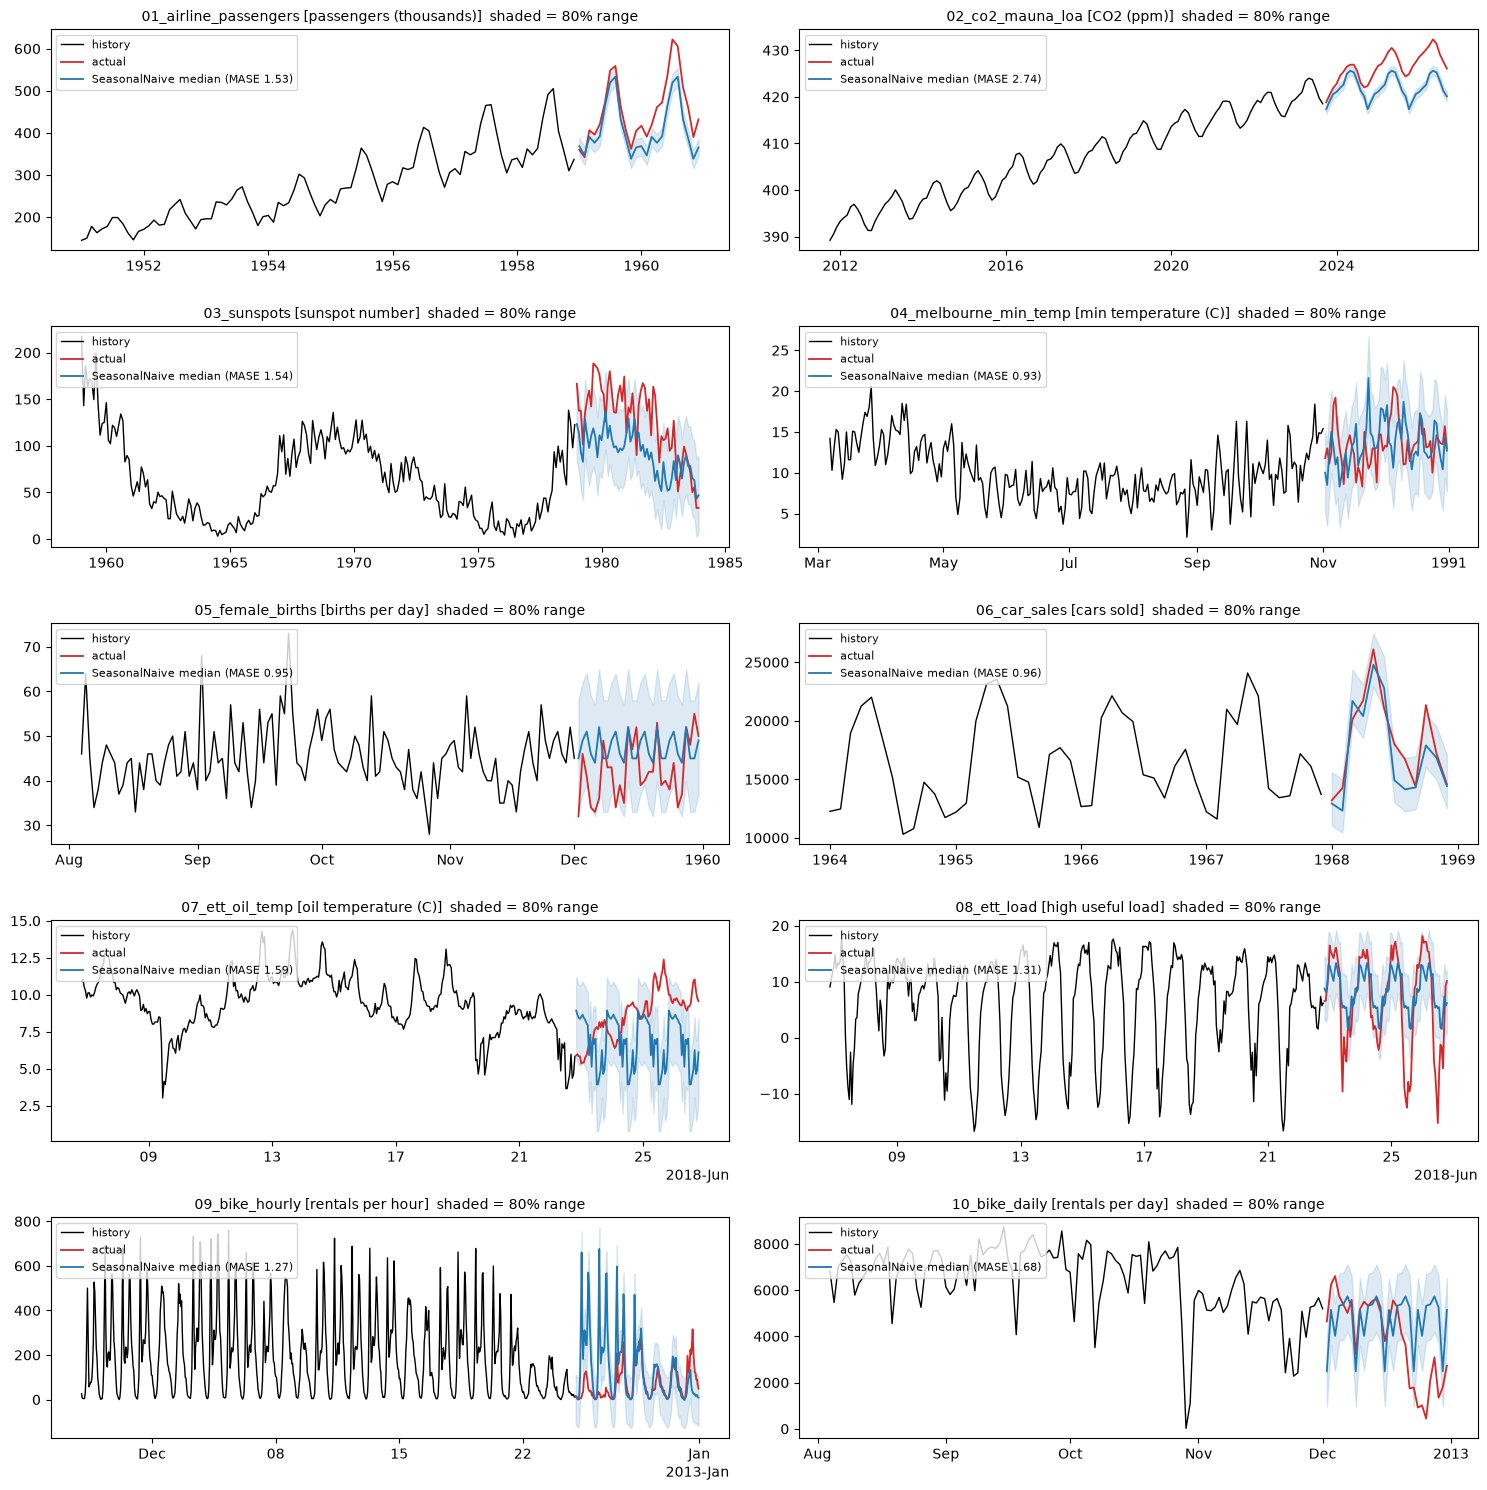

In [5]:
for name in SERIES:
    t = time.time()
    hist, test = split(name)
    y, m, h = hist.target.values, meta[name]["season"], len(test)
    med = np.array([y[len(y) - m + (i % m)] for i in range(h)])
    err = y[m:] - y[:-m]
    q = np.stack([med + np.quantile(err, p) for p in QUANTILES])
    record("SeasonalNaive", name, q, time.time() - t)
show_model("SeasonalNaive")

## 1. Toto 2.0 (Datadog)

> **What it does:** Toto 2.0 is a transformer forecaster from Datadog, trained mostly on observability metrics
> (CPU, memory, latency, request counts) plus public datasets. It cuts the history into patches of 32 steps
> and predicts the next patches, giving a full spread of quantiles instead of a single line.
> It can forecast several related series together (multivariate); this notebook forecasts each series on its own.
>
> | | |
> |---|---|
> | **Input** | `target`: history tensor `(batch, n_variates, time)`; `target_mask`: True where a value is observed; `series_ids`: which variates belong together |
> | **Output** | tensor `(9, batch, n_variates, horizon)`: quantiles 0.1, 0.2, …, 0.9 for each future step |
> | **Needs from you** | only the history and the horizon. No frequency, dates or covariates. |
>
> **Example (01_airline_passengers, 313m, first 3 months of 1959):** median `347, 336, 385` thousand passengers;
> the real values were `360, 342, 406`.
>
> **Implementation note:** the history length must be a multiple of 32. The helper left-pads with zeros and marks the padding
> `False` in `target_mask`, so the model treats it as missing.

Toto-313m: 313M params, quantiles [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


raw output shape for the last series: (9, 1, 1, 30) -> (quantiles, batch, variates, horizon)


,MAE,MASE,coverage_80,seconds
series,,,,
01_airline_passengers,50.36,1.76,29.17,0.45
02_co2_mauna_loa,0.90,0.56,58.33,0.42
03_sunspots,25.64,1.01,81.67,0.56
04_melbourne_min_temp,2.01,0.65,78.33,0.73
05_female_births,6.43,0.88,76.67,0.42
06_car_sales,2019.83,1.31,66.67,0.35
07_ett_oil_temp,0.94,0.54,96.88,0.64
08_ett_load,2.74,0.76,77.08,0.72
09_bike_hourly,45.44,0.64,92.86,0.68


Toto-313m: mean MASE 0.97 | mean coverage 72% | avg 0.54s per series | load 4.6s


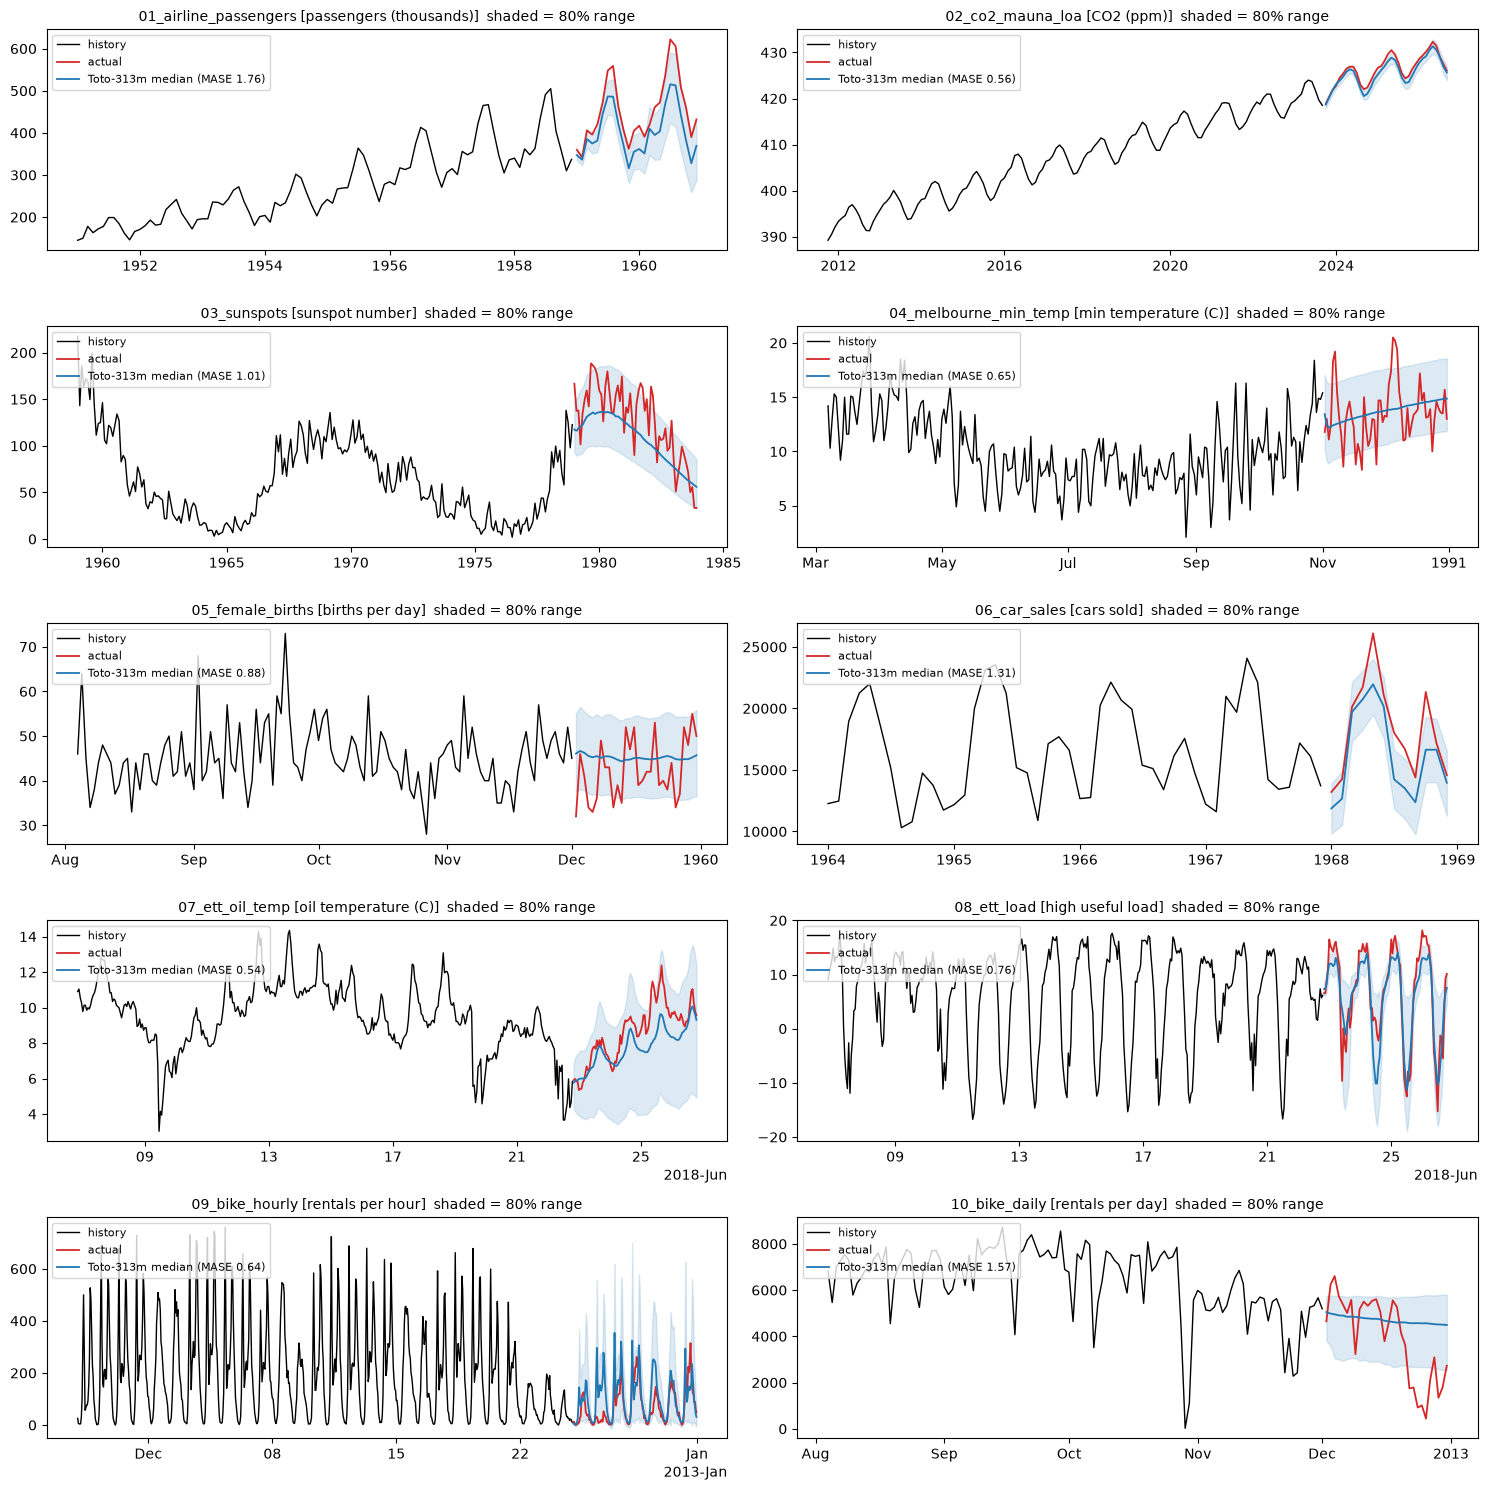

In [6]:
from toto2 import Toto2Model

t = time.time()
toto = Toto2Model.from_pretrained(f"Datadog/Toto-2.0-{TOTO_SIZE}").to(DEVICE).eval()
LOADS[f"Toto-{TOTO_SIZE}"] = time.time() - t
print(f"Toto-{TOTO_SIZE}: {sum(p.numel() for p in toto.parameters())/1e6:.0f}M params, quantiles {toto.output_head.knots}")

def toto_inputs(y, patch=toto.config.patch_size):
    y = torch.tensor(y, dtype=torch.float32)
    pad = (-len(y)) % patch
    x = torch.cat([torch.zeros(pad), y]).reshape(1, 1, -1)
    mask = torch.cat([torch.zeros(pad, dtype=torch.bool), torch.ones(len(y), dtype=torch.bool)]).reshape(1, 1, -1)
    return {"target": x.to(DEVICE), "target_mask": mask.to(DEVICE),
            "series_ids": torch.zeros(1, 1, dtype=torch.long, device=DEVICE)}

for name in SERIES:
    hist, test = split(name)
    t = time.time()
    with torch.no_grad():
        q = toto.forecast(toto_inputs(hist.target.values), horizon=len(test))   # (9, 1, 1, horizon)
    record(f"Toto-{TOTO_SIZE}", name, q[:, 0, 0].cpu().numpy(), time.time() - t)

print("raw output shape for the last series:", tuple(q.shape), "-> (quantiles, batch, variates, horizon)")
free(toto)
show_model(f"Toto-{TOTO_SIZE}")

## 2. TiRex-2 (NX-AI)

> **What it does:** TiRex-2 is a forecaster built on **xLSTM**, a modern recurrent network, instead of a transformer.
> It reads the series step by step and carries a compact memory forward, which keeps it small (~83M parameters) and fast.
> It can also use **covariates**: extra series that help explain the target (see section 4).
>
> | | |
> |---|---|
> | **Input** | a list of `TimeseriesType(target, past_covariates, future_covariates)`. `target` is `[n_targets, T]`. Past covariates are known only up to now; future covariates are known ahead, covering `T + horizon`. |
> | **Output** | one numpy array per series, `(n_targets, 9, horizon)`: quantiles 0.1, …, 0.9 |
> | **Needs from you** | the history and the horizon. Covariates are optional. |
>
> **Example (01_airline_passengers, first 3 months of 1959):** median `348, 342, 372`; actual `360, 342, 406`.

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 739.61it/s]

TiRex-2: 83M params


raw output shape for the last series: (1, 9, 30) -> (targets, quantiles, horizon)


,MAE,MASE,coverage_80,seconds
series,,,,
01_airline_passengers,56.60,1.98,8.33,0.22
02_co2_mauna_loa,1.08,0.66,100.00,0.11
03_sunspots,35.73,1.40,68.33,0.10
04_melbourne_min_temp,1.96,0.63,81.67,0.11
05_female_births,6.45,0.88,73.33,0.19
06_car_sales,1907.69,1.24,50.00,0.12
07_ett_oil_temp,0.92,0.53,96.88,0.12
08_ett_load,2.51,0.70,88.54,0.11
09_bike_hourly,60.97,0.86,80.36,0.11


TiRex-2: mean MASE 1.04 | mean coverage 71% | avg 0.13s per series | load 8.5s


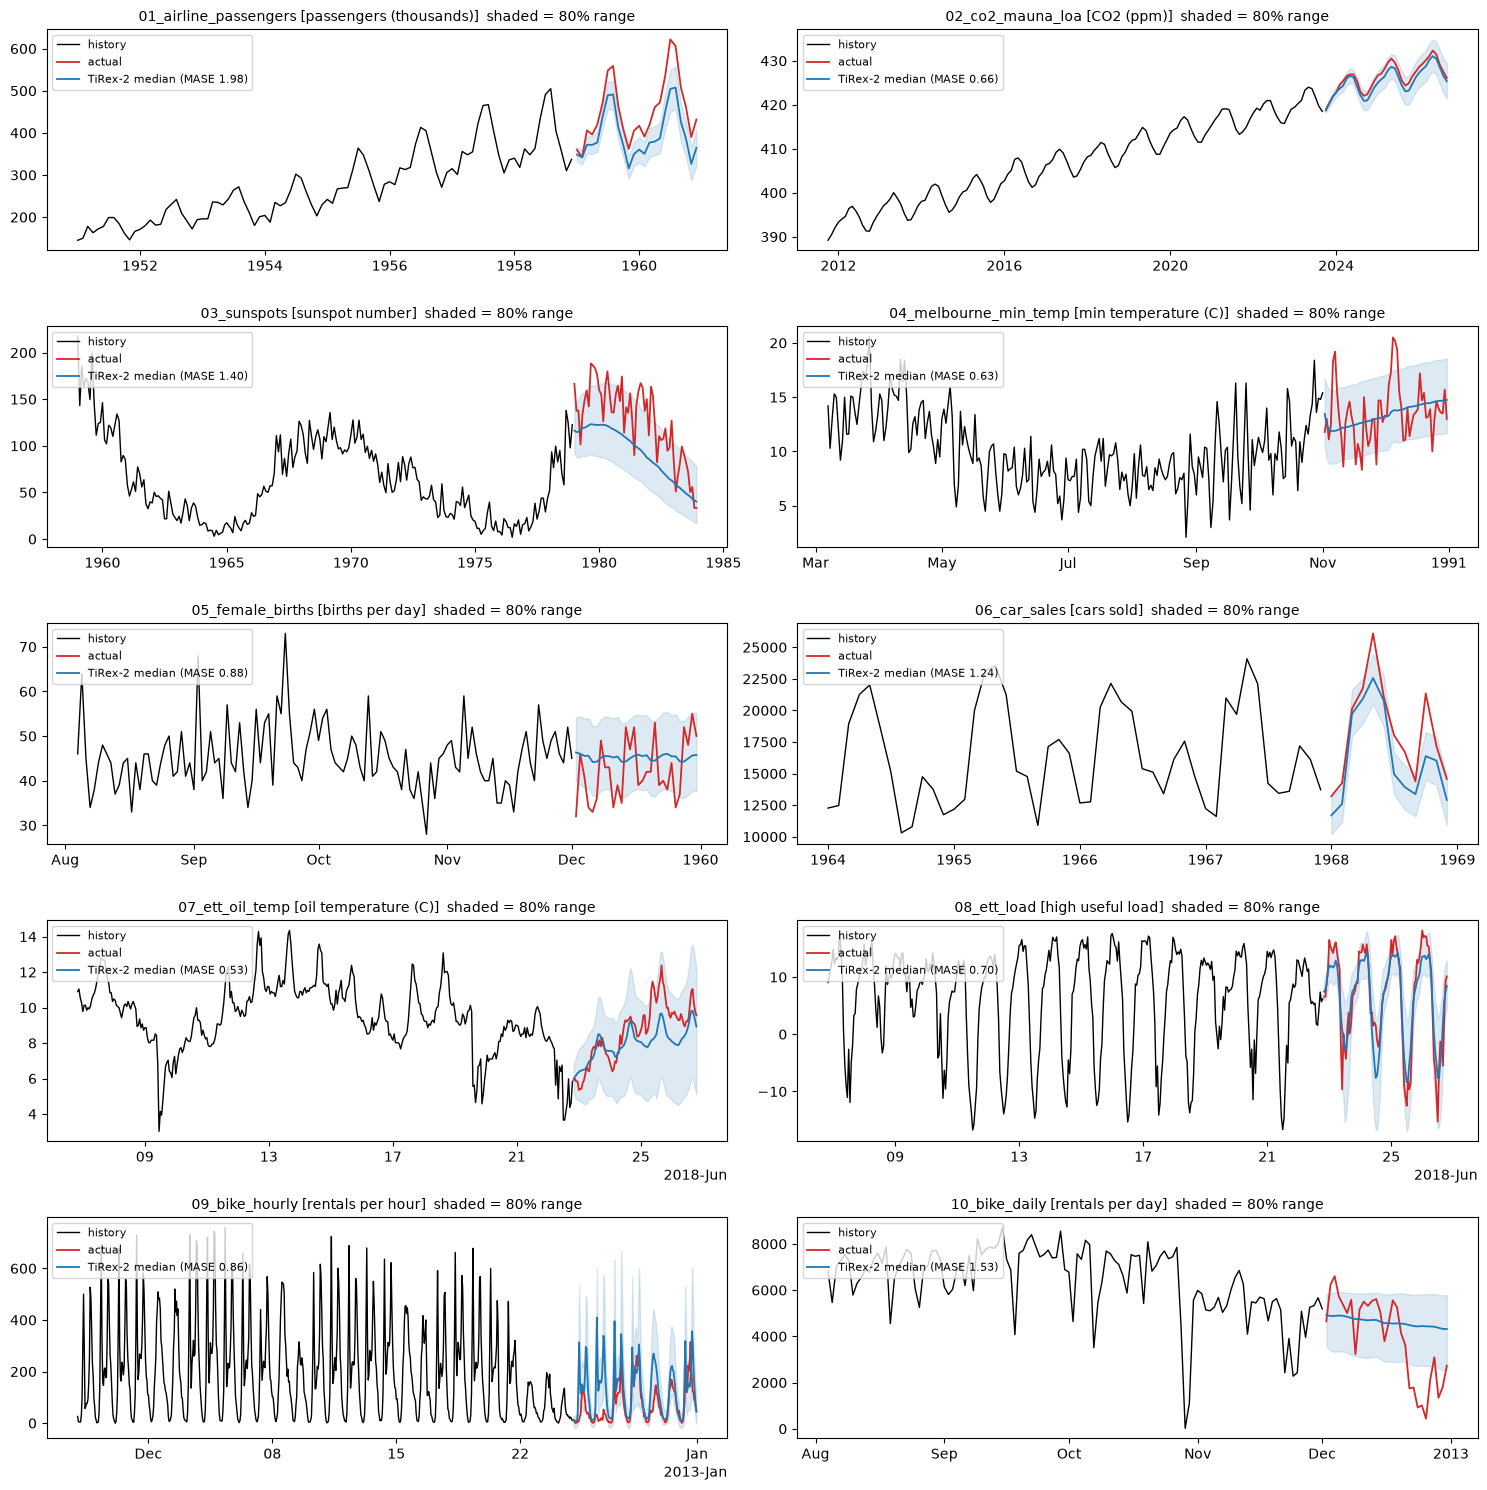

In [7]:
from tirex2 import TimeseriesType, load_model

t = time.time()
tirex = load_model("NX-AI/TiRex-2", device=DEVICE)
LOADS["TiRex-2"] = time.time() - t
print(f"TiRex-2: {sum(p.numel() for p in tirex.parameters())/1e6:.0f}M params")

for name in SERIES:
    hist, test = split(name)
    ts = TimeseriesType(target=torch.tensor(hist.target.values, dtype=torch.float32).unsqueeze(0),
                        past_covariates=None, future_covariates=None)
    t = time.time()
    fc = tirex.forecast([ts], prediction_length=len(test), output_type="numpy")[0]   # (1, 9, horizon)
    record("TiRex-2", name, fc[0], time.time() - t)

print("raw output shape for the last series:", fc.shape, "-> (targets, quantiles, horizon)")
show_model("TiRex-2")

## 3. Chronos-2 (Amazon)

> **What it does:** Chronos-2 is Amazon's encoder-only transformer forecaster. It reads the whole history at once
> and predicts all future steps in one pass, using 21 internal quantiles (0.01 to 0.99), so you can ask for any of them.
> It handles univariate, multivariate and covariate-informed forecasting, and can learn across several series in one batch.
>
> | | |
> |---|---|
> | **Input** | a long-format pandas DataFrame: `id`, `timestamp`, `target` (+ covariate columns). An optional `future_df` holds covariates known for the forecast window. |
> | **Output** | a DataFrame with one row per series per future step: `timestamp`, `predictions` (the median) and one column per requested quantile |
> | **Needs from you** | the history with timestamps and the horizon. Covariates are optional. |
>
> **Example (01_airline_passengers):**
>
> | timestamp | predictions | 0.1 | 0.5 | 0.9 |
> |---|---|---|---|---|
> | 1959-01-01 | 345.1 | 327.1 | 345.1 | 363.0 |
> | 1959-02-01 | 338.1 | 316.8 | 338.1 | 359.4 |
>
> The actual values were 360 and 342.

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights:  21%|██        | 35/170 [00:00<00:00, 322.88it/s]

Loading weights:  41%|████      | 70/170 [00:00<00:00, 335.80it/s]

Loading weights:  64%|██████▍   | 109/170 [00:00<00:00, 351.86it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 531.39it/s]

Chronos-2: 119M params


raw output for the last series (first 5 rows):


,id,timestamp,target_name,predictions,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9
0,10_bike_daily,2012-12-02,target,4870.812988,3572.895020,4127.165527,4444.586426,4679.829102,4870.812988,5048.292969,5218.847656,5409.221680,5675.234863
1,10_bike_daily,2012-12-03,target,4811.354492,3264.670410,3922.263428,4303.348633,4581.872070,4811.354492,5028.362305,5240.990234,5488.384766,5811.062500
2,10_bike_daily,2012-12-04,target,4822.539062,3205.970703,3897.511719,4295.971680,4583.426270,4822.539062,5049.060059,5274.044922,5541.233887,5888.690430
3,10_bike_daily,2012-12-05,target,4843.973633,3122.336914,3864.598145,4285.917969,4590.970215,4843.973633,5080.013672,5310.409668,5578.243652,5922.694336
4,10_bike_daily,2012-12-06,target,4872.995117,3143.712402,3896.525879,4316.599121,4619.153320,4872.995117,5115.073730,5351.759766,5629.204590,5983.965332


,MAE,MASE,coverage_80,seconds
series,,,,
01_airline_passengers,36.95,1.29,62.50,0.10
02_co2_mauna_loa,0.92,0.56,86.11,0.11
03_sunspots,20.65,0.81,96.67,0.24
04_melbourne_min_temp,1.95,0.63,81.67,0.36
05_female_births,6.09,0.83,83.33,0.10
06_car_sales,1288.16,0.83,83.33,0.06
07_ett_oil_temp,0.91,0.53,96.88,0.25
08_ett_load,2.60,0.72,77.08,0.27
09_bike_hourly,86.00,1.21,57.14,0.25


Chronos-2: mean MASE 0.90 | mean coverage 79% | avg 0.18s per series | load 1.4s


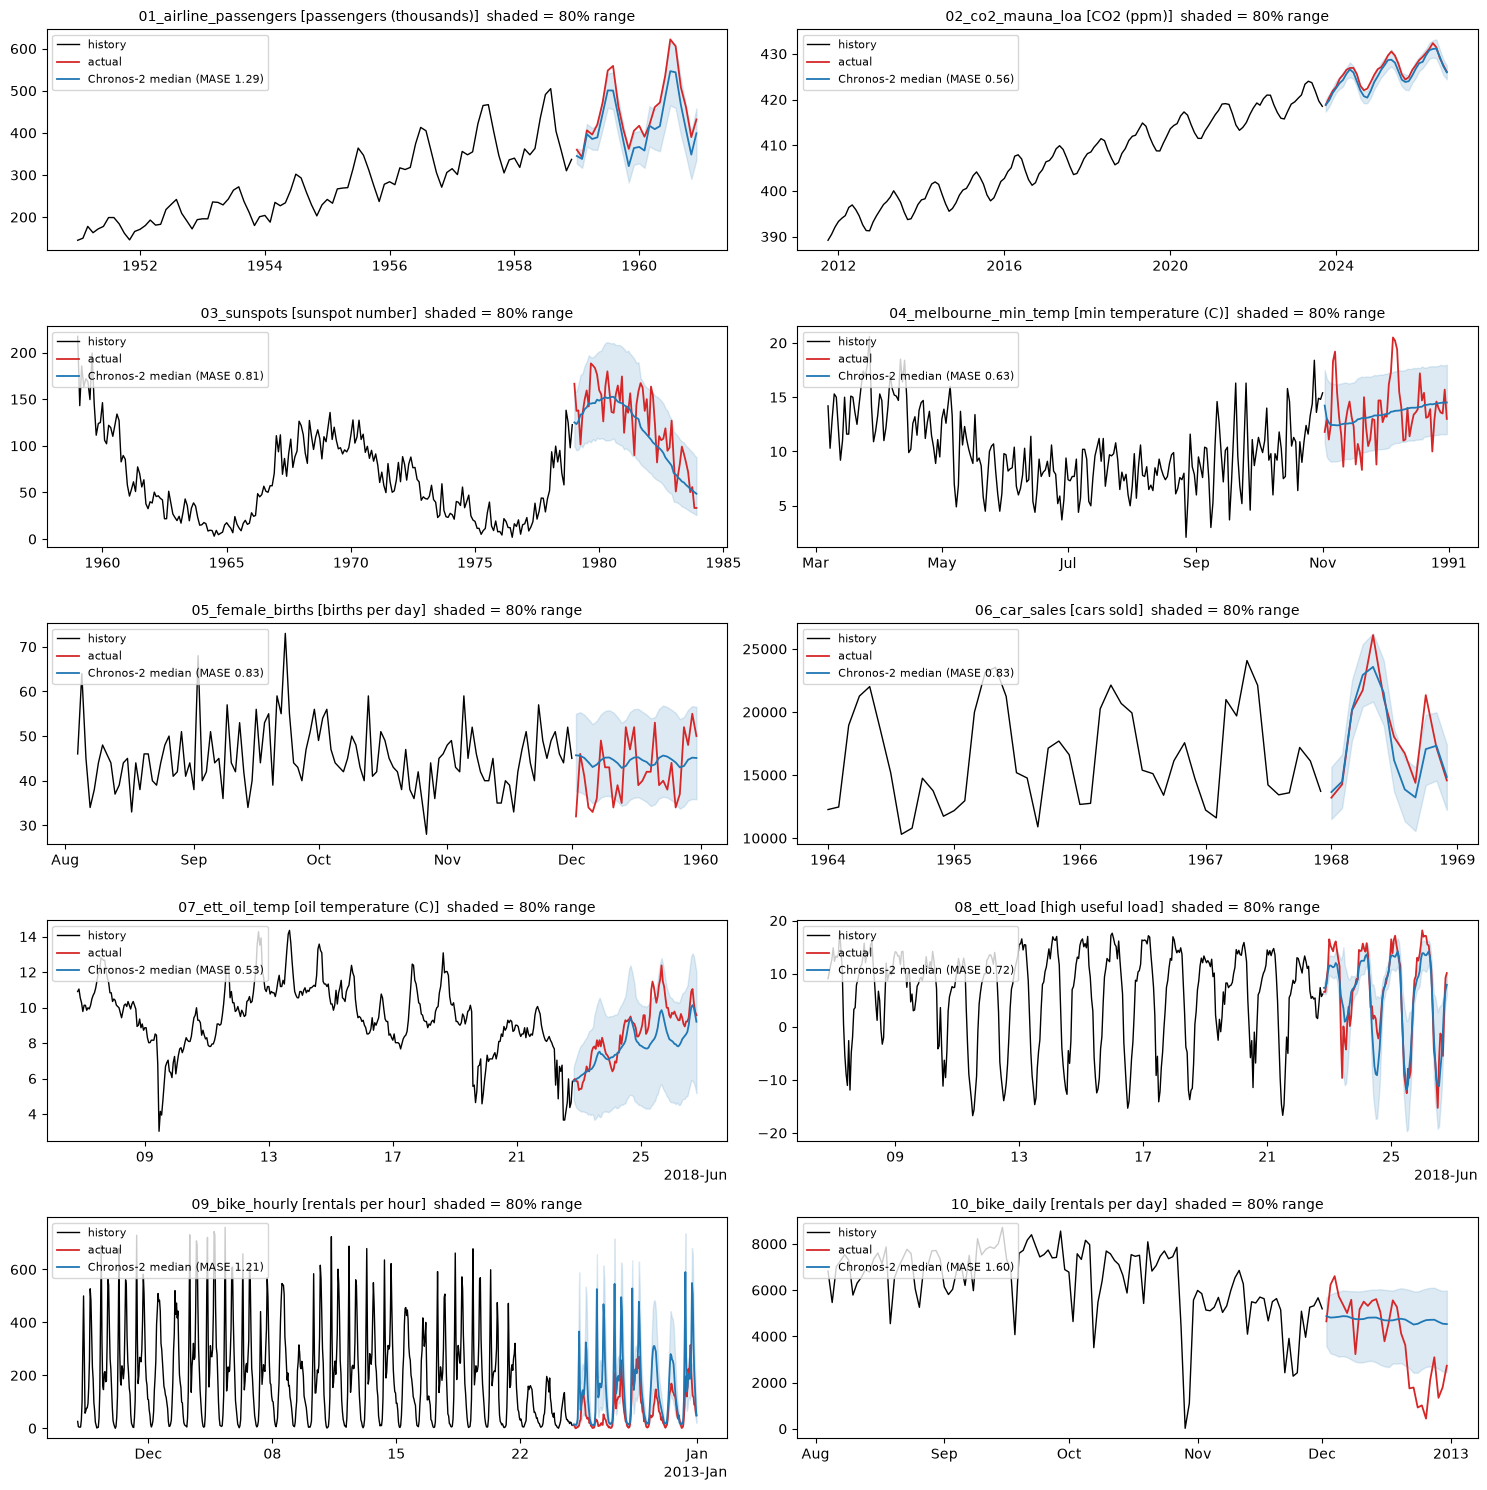

In [8]:
from chronos import Chronos2Pipeline

t = time.time()
chronos = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE)
LOADS["Chronos-2"] = time.time() - t
print(f"Chronos-2: {sum(p.numel() for p in chronos.model.parameters())/1e6:.0f}M params")

for name in SERIES:
    hist, test = split(name)
    t = time.time()
    pred = chronos.predict_df(hist[["timestamp", "target"]].assign(id=name), id_column="id",
                              prediction_length=len(test), quantile_levels=QUANTILES)
    record("Chronos-2", name, pred[[str(q) for q in QUANTILES]].values.T, time.time() - t)

print("raw output for the last series (first 5 rows):")
display(pred.head())
show_model("Chronos-2")

## 4. Covariates: does extra information help? (10_bike_daily)

**Covariates** are extra series that help explain the target. Here the target is daily bike rentals, and the covariates are:
- **`workingday`** (1 = weekday, 0 = weekend or holiday): truly known in advance.
- **`temp`** (°C): only known in advance from a weather forecast. Here the real future temperature is used, which is a little optimistic.

Both are given as *future-known* covariates, covering the history and the 30 forecast days. Toto 2.0 is left out because
this notebook only uses it on the target.

,MAE,MASE,coverage_80
TiRex-2,1402.30,1.53,66.67
TiRex-2 +cov,1376.70,1.50,66.67
Chronos-2,1468.73,1.60,66.67
Chronos-2 +cov,1417.49,1.55,60.00


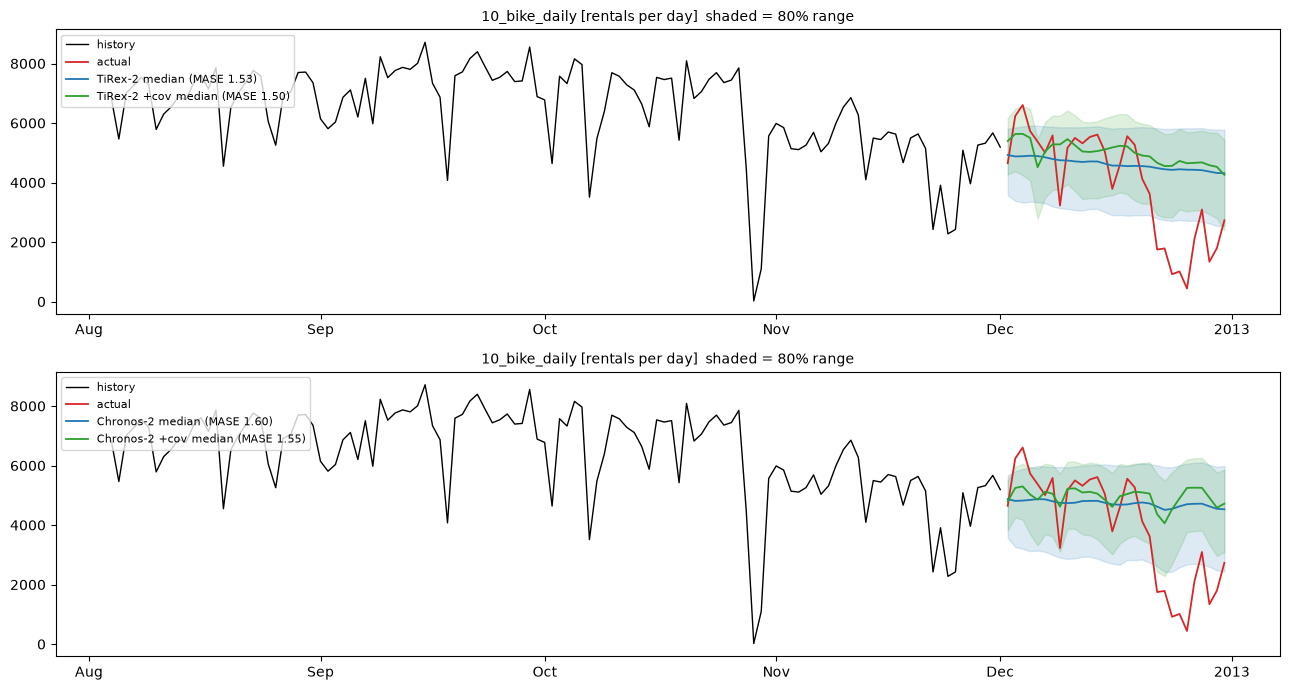

In [9]:
name, COVS = "10_bike_daily", ["workingday", "temp"]
hist, test = split(name)
df = SERIES[name]

# TiRex-2: future covariates are a [n_covariates, T + horizon] tensor
y = torch.tensor(hist.target.values, dtype=torch.float32).unsqueeze(0)
fut = torch.tensor(df[COVS].values.T, dtype=torch.float32)
t = time.time()
fc = tirex.forecast([TimeseriesType(target=y, past_covariates=None, future_covariates=fut)],
                    prediction_length=len(test), output_type="numpy")[0]
record("TiRex-2 +cov", name, fc[0], time.time() - t)

# Chronos-2: covariate columns in the history, and their future values in future_df
t = time.time()
pred = chronos.predict_df(hist[["timestamp", "target"] + COVS].assign(id=name),
                          future_df=test[["timestamp"] + COVS].assign(id=name),
                          id_column="id", prediction_length=len(test), quantile_levels=QUANTILES)
record("Chronos-2 +cov", name, pred[[str(q) for q in QUANTILES]].values.T, time.time() - t)

cmp = pd.DataFrame({m: scores(name, FORECASTS[m][name])
                    for m in ["TiRex-2", "TiRex-2 +cov", "Chronos-2", "Chronos-2 +cov"]}).T
display(cmp.round(2))
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
plot_forecast(name, ["TiRex-2", "TiRex-2 +cov"], ax=axes[0])
plot_forecast(name, ["Chronos-2", "Chronos-2 +cov"], ax=axes[1])
plt.tight_layout(); plt.show()
free(tirex, chronos)

## 5. Summary across all 10 series

Lower MASE is better; below 1.0 beats the seasonal-naive rule. The best model per series is shown in **bold**.

In [10]:
MAIN = ["SeasonalNaive", f"Toto-{TOTO_SIZE}", "TiRex-2", "Chronos-2"]
mase = pd.DataFrame({m: {n: scores(n, FORECASTS[m][n])["MASE"] for n in SERIES} for m in MAIN})
cover = pd.DataFrame({m: {n: scores(n, FORECASTS[m][n])["coverage_80"] for n in SERIES} for m in MAIN})

print("MASE per series (lower is better)")
display(mase.style.format("{:.2f}").highlight_min(axis=1, props="font-weight:bold"))

summary = pd.DataFrame({
    "mean MASE": mase.mean(),
    "wins (best MASE)": mase.idxmin(axis=1).value_counts().reindex(MAIN, fill_value=0),
    "mean 80% coverage (%)": cover.mean(),
    "load s": pd.Series(LOADS),
    "avg s / series": pd.Series({m: np.mean(list(TIMES[m].values())) for m in MAIN}),
}).loc[MAIN]
display(summary.round(2))
summary.round(3).to_csv(OUT / "summary.csv")

rows = []
for model, per in FORECASTS.items():
    for name, q in per.items():
        test = split(name)[1]
        for i, (ts, actual) in enumerate(zip(test.timestamp, test.target)):
            rows.append({"model": model, "series": name, "step": i + 1, "timestamp": ts, "actual": actual,
                         **{f"q{p}": q[j, i] for j, p in enumerate(QUANTILES)}})
pd.DataFrame(rows).to_csv(OUT / "forecasts.csv", index=False)
print("saved", OUT / "summary.csv", "and", OUT / "forecasts.csv", f"({len(rows)} rows)")

MASE per series (lower is better)


,SeasonalNaive,Toto-313m,TiRex-2,Chronos-2
01_airline_passengers,1.53,1.76,1.98,1.29
02_co2_mauna_loa,2.74,0.56,0.66,0.56
03_sunspots,1.54,1.01,1.40,0.81
04_melbourne_min_temp,0.93,0.65,0.63,0.63
05_female_births,0.95,0.88,0.88,0.83
06_car_sales,0.96,1.31,1.24,0.83
07_ett_oil_temp,1.59,0.54,0.53,0.53
08_ett_load,1.31,0.76,0.70,0.72
09_bike_hourly,1.27,0.64,0.86,1.21
10_bike_daily,1.68,1.57,1.53,1.60


,mean MASE,wins (best MASE),mean 80% coverage (%),load s,avg s / series
SeasonalNaive,1.45,0,60.02,NaN,0.00
Toto-313m,0.97,2,72.43,4.65,0.54
TiRex-2,1.04,2,71.41,8.47,0.13
Chronos-2,0.90,6,79.14,1.38,0.18


saved outputs/summary.csv and outputs/forecasts.csv (2508 rows)


**What this run showed (CPU, 8-core laptop):**
- **Chronos-2** had the best average (mean MASE 0.90, best on 6 of 10 series), and its 80% ranges were the best calibrated (79% coverage).
- **Toto 2.0 313m** (0.97) and **TiRex-2** (1.04) were close behind. Toto was best on hourly bike rentals; TiRex-2 was the fastest (~0.17 s per series).
- **All three beat the seasonal-naive rule on average** (1.45), but not on every series:
  - **Airline passengers:** Toto and TiRex-2 underpredicted 1959–60's growth, and their 80% ranges caught only 29% and 8% of the real values.
  - **Daily bikes (December 2012):** nobody beat the naive rule. The holiday drop isn't predictable from the history.
- **Covariates** (`workingday`, `temp`) helped both models a little on daily bikes (MASE 1.53 → 1.50 and 1.60 → 1.55).
- These are 10 series with one forecast window each, so treat the ranking as a rough first impression, not a benchmark.

## 6. Side-by-side: all models on each series

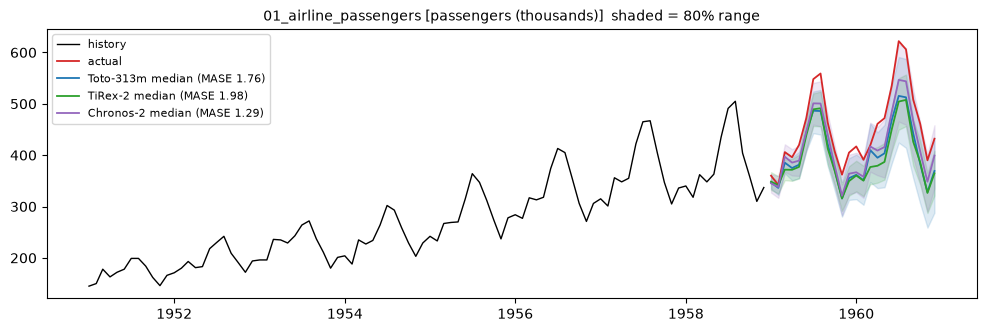

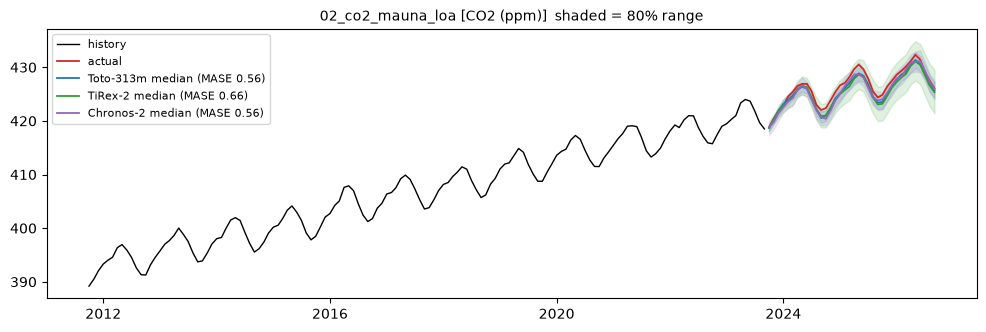

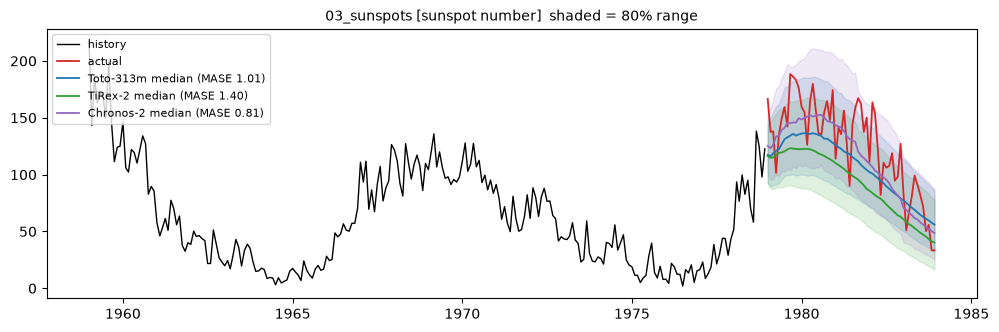

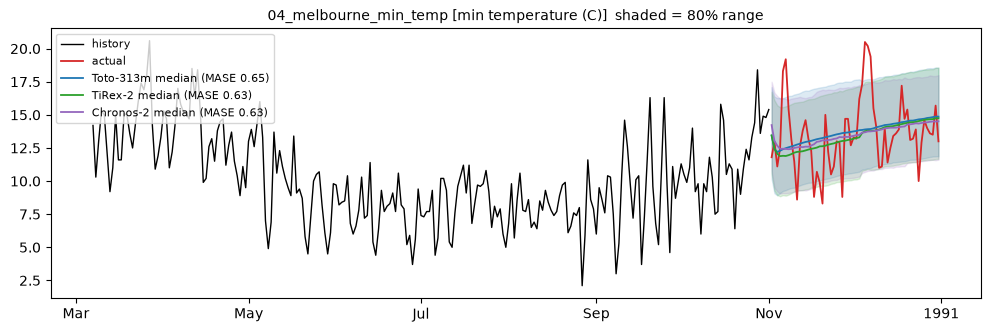

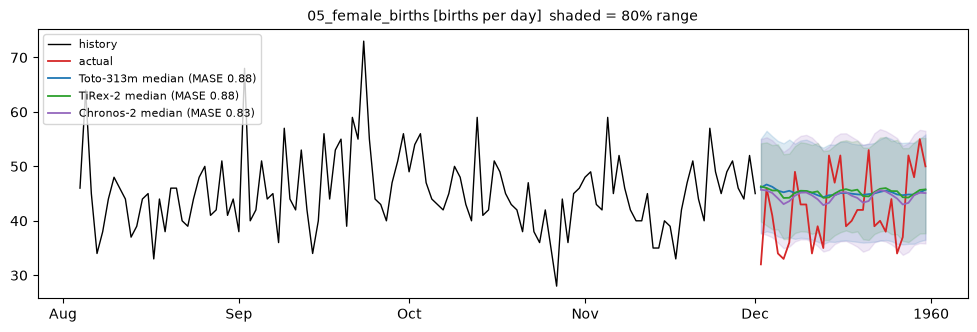

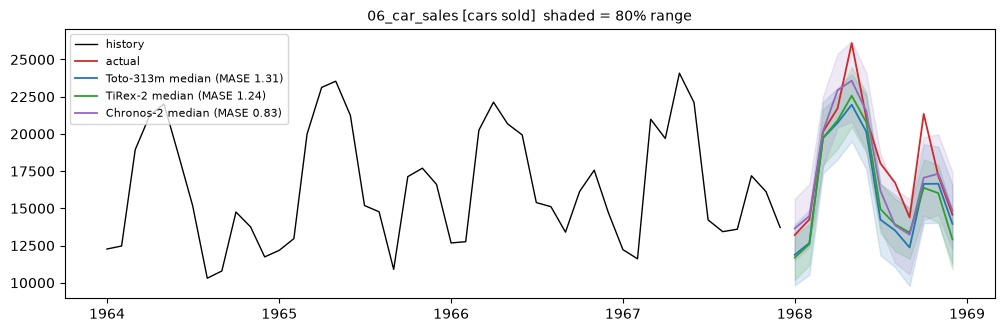

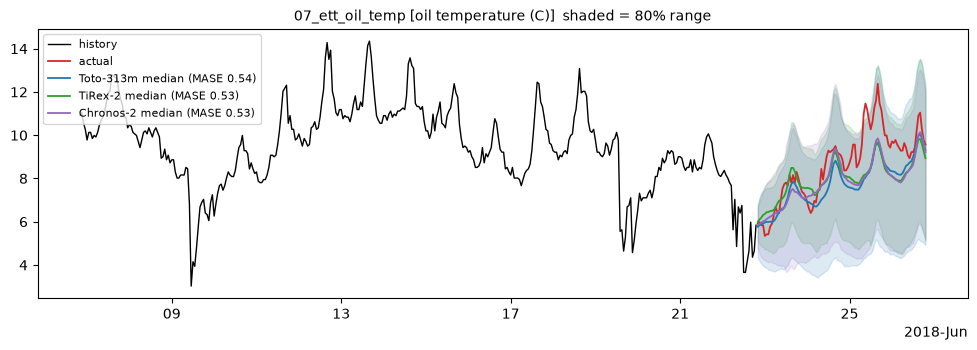

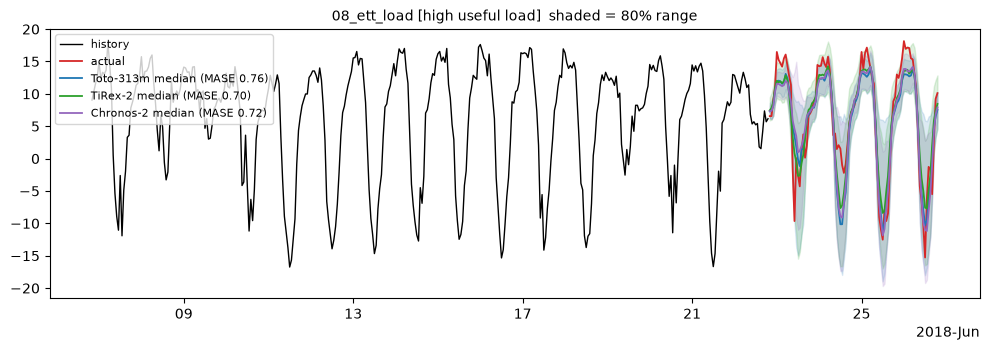

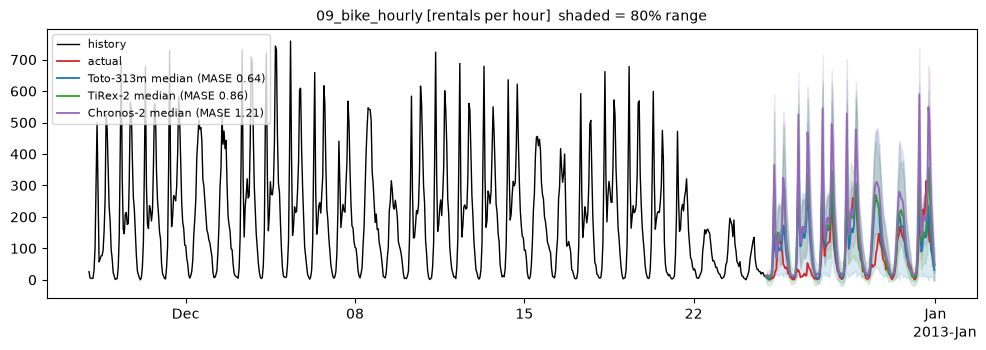

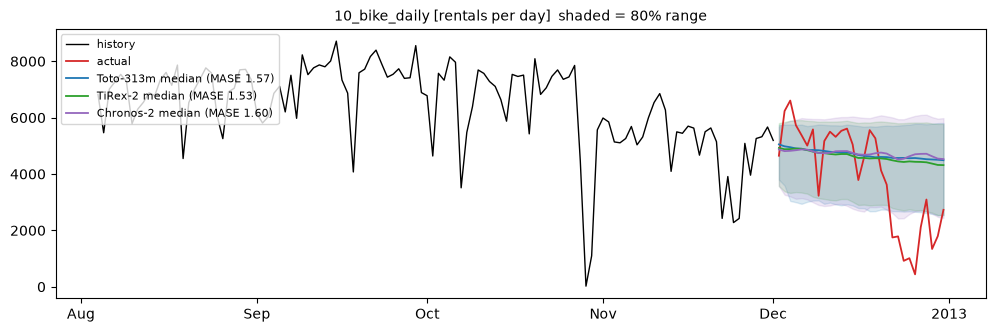

In [11]:
def compare(name, models=MAIN[1:]):
    ax = plot_forecast(name, models)
    ax.figure.savefig(OUT / "plots" / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

for name in SERIES:
    compare(name)

## 7. What the raw output looks like

This is one model's full answer for one series: 9 quantiles for each future step, next to the real value.

In [12]:
name, model = "06_car_sales", "Chronos-2"
q, test = FORECASTS[model][name], split(name)[1]
raw = pd.DataFrame(q.T, columns=[f"q{p}" for p in QUANTILES], index=test.timestamp.dt.strftime("%Y-%m"))
raw.insert(0, "actual", test.target.values)
display(raw.round(0))

,actual,q0.1,q0.2,q0.3,q0.4,q0.5,q0.6,q0.7,q0.8,q0.9
timestamp,,,,,,,,,,
1968-01,13210.0,11514.0,12292.0,12809.0,13241.0,13652.0,14046.0,14440.0,14929.0,15645.0
1968-02,14251.0,12393.0,13155.0,13655.0,14075.0,14483.0,14915.0,15353.0,15883.0,16633.0
1968-03,20139.0,17762.0,18628.0,19229.0,19718.0,20187.0,20630.0,21109.0,21740.0,22532.0
1968-04,21725.0,20433.0,21366.0,21972.0,22492.0,22934.0,23439.0,23892.0,24506.0,25374.0
1968-05,26099.0,20830.0,21934.0,22638.0,23162.0,23580.0,24026.0,24555.0,25313.0,26233.0
1968-06,21084.0,18918.0,19932.0,20580.0,21082.0,21527.0,22023.0,22484.0,23136.0,24089.0
1968-07,18024.0,13700.0,14600.0,15216.0,15717.0,16177.0,16637.0,17096.0,17697.0,18653.0
1968-08,16722.0,11347.0,12279.0,12902.0,13403.0,13864.0,14323.0,14781.0,15369.0,16272.0
1968-09,14385.0,10563.0,11595.0,12242.0,12758.0,13231.0,13702.0,14182.0,14779.0,15614.0
